# InternCircle - Project 04: First Machine Learning Classifier
**Domain:** Data Science & AI | **Level:** Intermediate  
**Target:** Titanic Survival Classification with Scikit-Learn Decision Trees

---

### Project Overview
In this project, we build, evaluate, and interpret a supervised machine learning classifier using Scikit-Learn to predict whether passengers survived the Titanic disaster. We follow an end-to-end disciplined ML workflow:
1. **Define the prediction problem**
2. **Prepare and clean the dataset**
3. **Split into training and testing sets (stratified)**
4. **Establish a naive baseline**
5. **Train a Decision Tree Classifier (`max_depth=4`)**
6. **Evaluate using Accuracy, Confusion Matrix, and feature importances**
7. **Investigate tree depth and overfitting across depths 1 to 12**
8. **Synthesize key learnings and honest model limitations**


In [1]:
# Core Libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn Modules
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Visual Styling
sns.set_theme(style="whitegrid")
plt.rcParams["font.size"] = 11


## Step 1: Define the Prediction

> **Problem Definition Statement:**  
> **"Predict whether a passenger survived from their class, sex, age and fare. Survived is the target; the rest are features."**

* **Target Variable ($y$):** `survived` (Binary: `0` = Did not survive, `1` = Survived)
* **Feature Variables ($X$):**
  * `pclass`: Passenger socio-economic class (1 = 1st, 2 = 2nd, 3 = 3rd)
  * `sex`: Passenger gender (binary encoded to female=1, male=0)
  * `age`: Passenger age in years
  * `fare`: Ticket fare paid in British pounds


## Step 2: Prepare the Data
We load the Titanic dataset, select the five required columns, handle missing values via `dropna()`, and convert `sex` into binary numerical values (`female` = 1, `male` = 0).


In [2]:
# Load the Titanic dataset (supports online seaborn loading or local fallback)
try:
    raw_df = sns.load_dataset("titanic")
except Exception:
    raw_df = pd.read_csv("titanic.csv")

print(f"Original dataset shape: {raw_df.shape}")

# Select the target and specified features
df = raw_df[["survived", "pclass", "sex", "age", "fare"]].dropna().copy()
print(f"Shape after dropping rows with missing values (dropna): {df.shape}")

# Encode 'sex': female -> 1, male -> 0
df["sex"] = (df["sex"] == "female").astype(int)

# Separate features (X) and target (y)
X = df.drop(columns="survived")
y = df["survived"]

print(f"Features (X): {list(X.columns)}")
print(f"Target (y): 'survived'\n")
print("Class distribution in target variable y:")
print(y.value_counts(normalize=True).round(3))


Original dataset shape: (891, 15)
Shape after dropping rows with missing values (dropna): (714, 5)
Features (X): ['pclass', 'sex', 'age', 'fare']
Target (y): 'survived'

Class distribution in target variable y:
survived
0    0.594
1    0.406
Name: proportion, dtype: float64


## Step 3: Split the Data into Training and Testing Sets
We partition the dataset into 80% training and 20% test subsets. We fix `random_state=42` for exact reproducibility and use `stratify=y` to ensure both subsets preserve identical proportions of survivors and non-survivors.


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Total samples:     {len(df)}")
print(f"Training samples:  {len(X_train)} ({len(X_train)/len(df)*100:.1f}%)")
print(f"Testing samples:   {len(X_test)} ({len(X_test)/len(df)*100:.1f}%)")
print(f"Train survival rate: {y_train.mean():.4f}")
print(f"Test survival rate:  {y_test.mean():.4f}")


Total samples:     714
Training samples:  571 (80.0%)
Testing samples:   143 (20.0%)
Train survival rate: 0.4063
Test survival rate:  0.4056


## Step 4: Set a Baseline
A machine learning model is only meaningful if it outperforms a simple heuristic. A standard baseline for imbalanced binary classification is the **majority-class classifier**: always predicting the most frequent outcome (in this case, "Did not survive" = 0).


In [4]:
# Baseline accuracy = proportion of the majority class in the test set
prob_died = 1 - y_test.mean()
prob_survived = y_test.mean()
baseline = max(prob_survived, prob_died)

print(f"Test Set Did Not Survive (0): {prob_died:.4f} ({prob_died*100:.1f}%)")
print(f"Test Set Survived (1):         {prob_survived:.4f} ({prob_survived*100:.1f}%)")
print(f"Baseline Accuracy (always guess 0): {round(baseline, 3)} ({baseline*100:.1f}%)")
print("--> Any trained model MUST score significantly above 59.4% to be useful.")


Test Set Did Not Survive (0): 0.5944 (59.4%)
Test Set Survived (1):         0.4056 (40.6%)
Baseline Accuracy (always guess 0): 0.594 (59.4%)
--> Any trained model MUST score significantly above 59.4% to be useful.


## Step 5: Train the Decision Tree Classifier
We instantiate `DecisionTreeClassifier` with `max_depth=4` and `random_state=42`, and fit it **strictly** on the training data (`X_train`, `y_train`).


In [5]:
# Instantiate and fit model on training set only
model = DecisionTreeClassifier(max_depth=4, random_state=42)
model.fit(X_train, y_train)

print("DecisionTreeClassifier(max_depth=4, random_state=42) fitted successfully.")


DecisionTreeClassifier(max_depth=4, random_state=42) fitted successfully.


## Step 6: Evaluate on the Test Set
We evaluate how well the trained model generalizes to unseen test instances using **Accuracy** and a **Confusion Matrix**.


In [6]:
# Make predictions on both train and test sets
train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

train_acc = accuracy_score(y_train, train_pred)
test_acc = accuracy_score(y_test, test_pred)
cm = confusion_matrix(y_test, test_pred)

print(f"Baseline accuracy:        {round(baseline, 3)}")
print(f"Model Training accuracy:  {round(train_acc, 3)}")
print(f"Model Test accuracy:      {round(test_acc, 3)}")
print(f"Improvement over baseline: +{(test_acc - baseline)*100:.1f}%")
print("\nConfusion Matrix:")
print(cm)


Baseline accuracy:        0.594
Model Training accuracy:  0.848
Model Test accuracy:      0.797
Improvement over baseline: +20.3%

Confusion Matrix:
[[72 13]
 [16 42]]


### Detailed Cell-by-Cell Breakdown of the Confusion Matrix

The confusion matrix for binary classification maps actual ground truth against model predictions:

| | Predicted: Died (0) | Predicted: Survived (1) |
|---|---|---|
| **Actual: Died (0)** | **True Negative (TN) = 72** | **False Positive (FP) = 13** |
| **Actual: Survived (1)** | **False Negative (FN) = 16** | **True Positive (TP) = 42** |

1. **True Negatives (TN = 72):**  
   Passengers who died, and the model correctly predicted they died.
2. **False Positives (FP = 13 - Type I Error):**  
   Passengers who died, but the model mistakenly predicted they survived.
3. **False Negatives (FN = 16 - Type II Error):**  
   Passengers who actually survived, but the model incorrectly predicted they died.
4. **True Positives (TP = 42):**  
   Passengers who survived, and the model correctly predicted they survived.


Detailed Classification Report:

              precision    recall  f1-score   support

    Died (0)       0.82      0.85      0.83        85
Survived (1)       0.76      0.72      0.74        58

    accuracy                           0.80       143
   macro avg       0.79      0.79      0.79       143
weighted avg       0.80      0.80      0.80       143


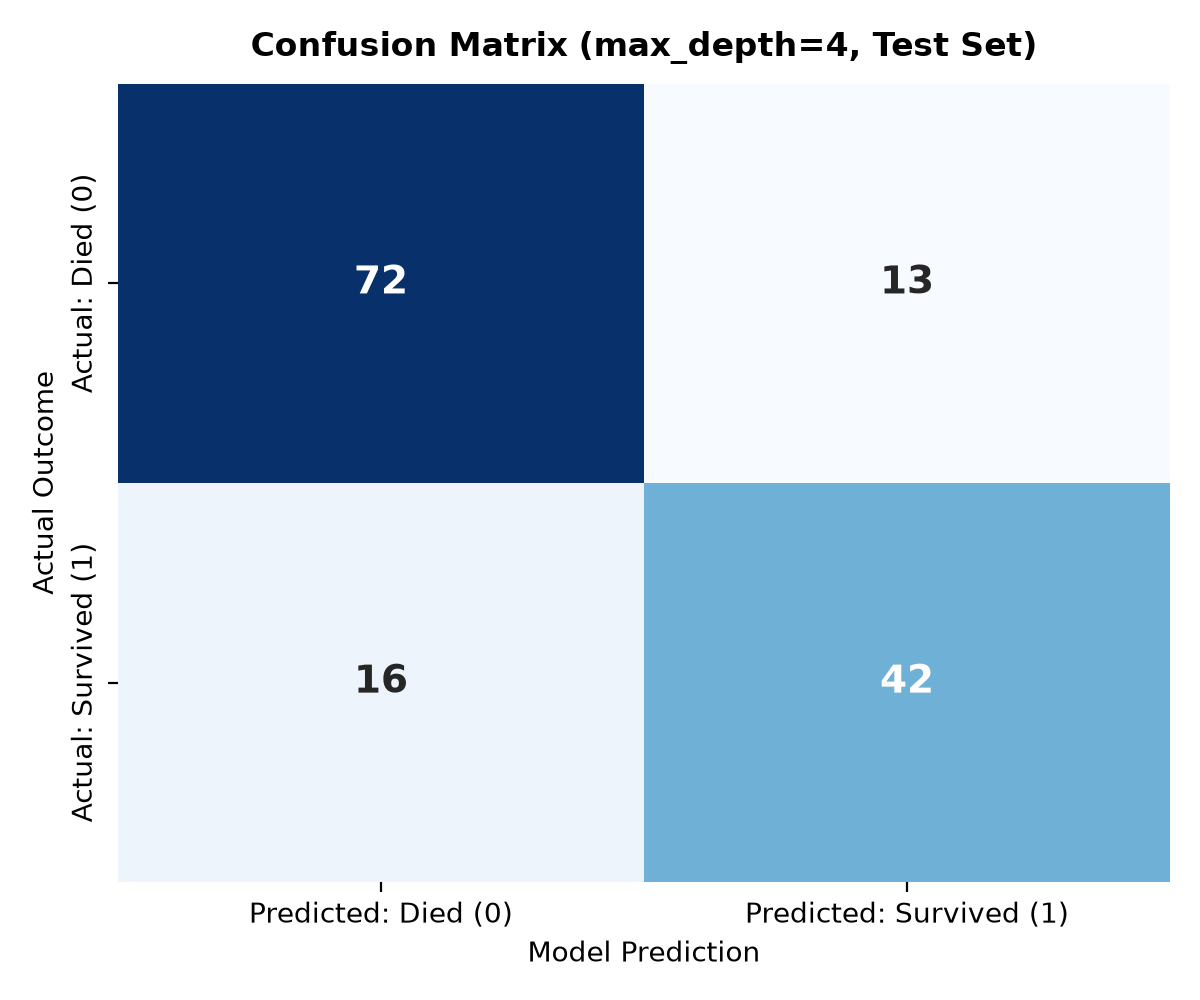

In [7]:
# Visualizing the Confusion Matrix Heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Predicted: Died (0)", "Predicted: Survived (1)"],
    yticklabels=["Actual: Died (0)", "Actual: Survived (1)"],
    annot_kws={"size": 14, "weight": "bold"}
)
plt.title("Confusion Matrix (max_depth=4, Test Set)", fontsize=13, fontweight="bold", pad=12)
plt.ylabel("Actual Outcome", fontsize=11)
plt.xlabel("Model Prediction", fontsize=11)
plt.tight_layout()
plt.show()

# Classification Report
print("Detailed Classification Report:\n")
print(classification_report(y_test, test_pred, target_names=["Died (0)", "Survived (1)"]))


### Feature Importances
We extract `model.feature_importances_` to assess which features contributed most to Gini impurity reduction across tree splits.


Feature Importances: {'pclass': 0.24, 'sex': 0.55, 'age': 0.14, 'fare': 0.08}


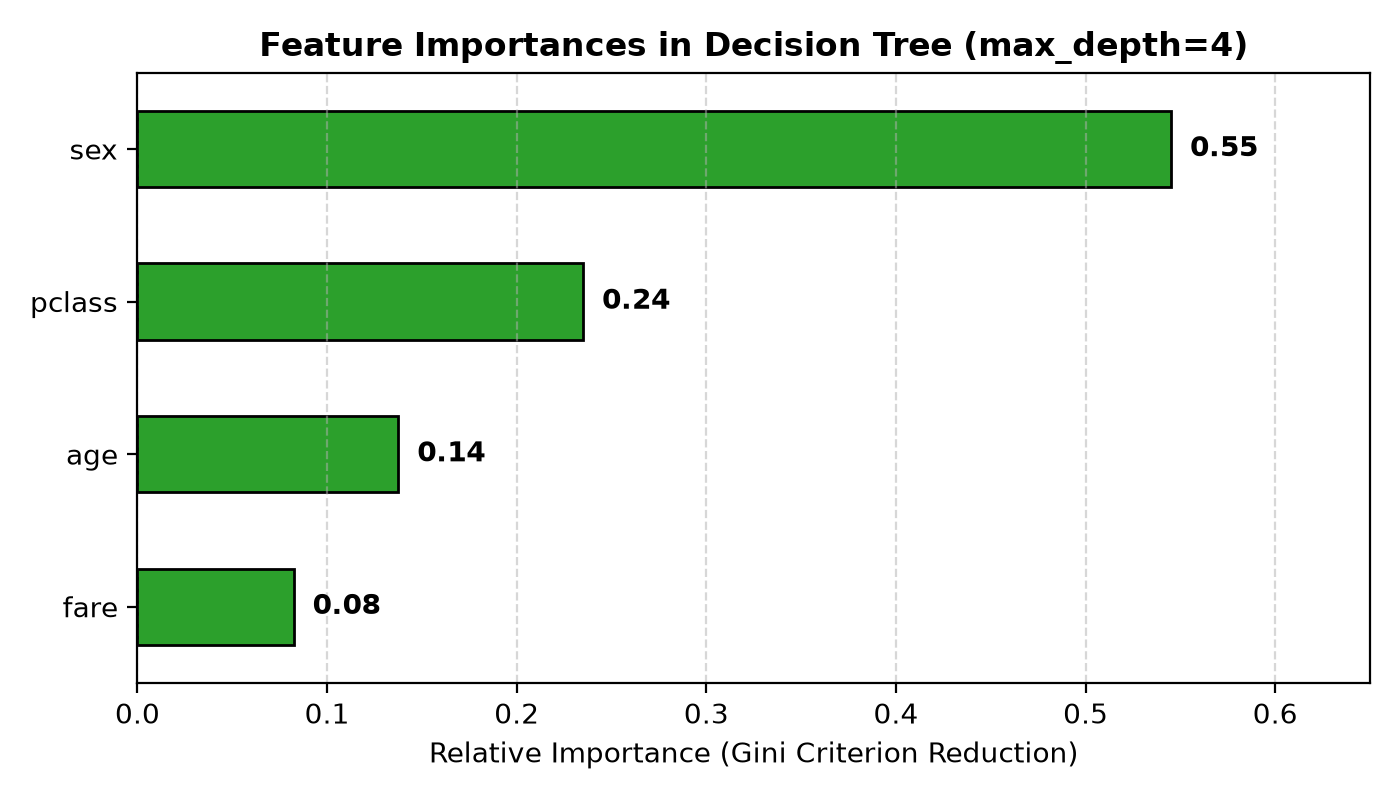

In [8]:
# Feature importances
importances = dict(zip(X.columns, model.feature_importances_.round(2).tolist()))
print("Feature Importances:", importances)

# Bar chart of feature importances
plt.figure(figsize=(7, 4))
fi_series = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=True)
fi_series.plot(kind="barh", color="#2ca02c", edgecolor="black")
plt.title("Feature Importances (max_depth=4)", fontsize=12, fontweight="bold")
plt.xlabel("Relative Importance (Gini Impurity Reduction)", fontsize=10)
for index, value in enumerate(fi_series):
    plt.text(value + 0.01, index, f"{value:.2f}", va="center", fontweight="bold")
plt.xlim(0, 0.65)
plt.tight_layout()
plt.show()


### Visualizing the Decision Tree Architecture
Let us examine the exact splitting rules determined by the decision tree.


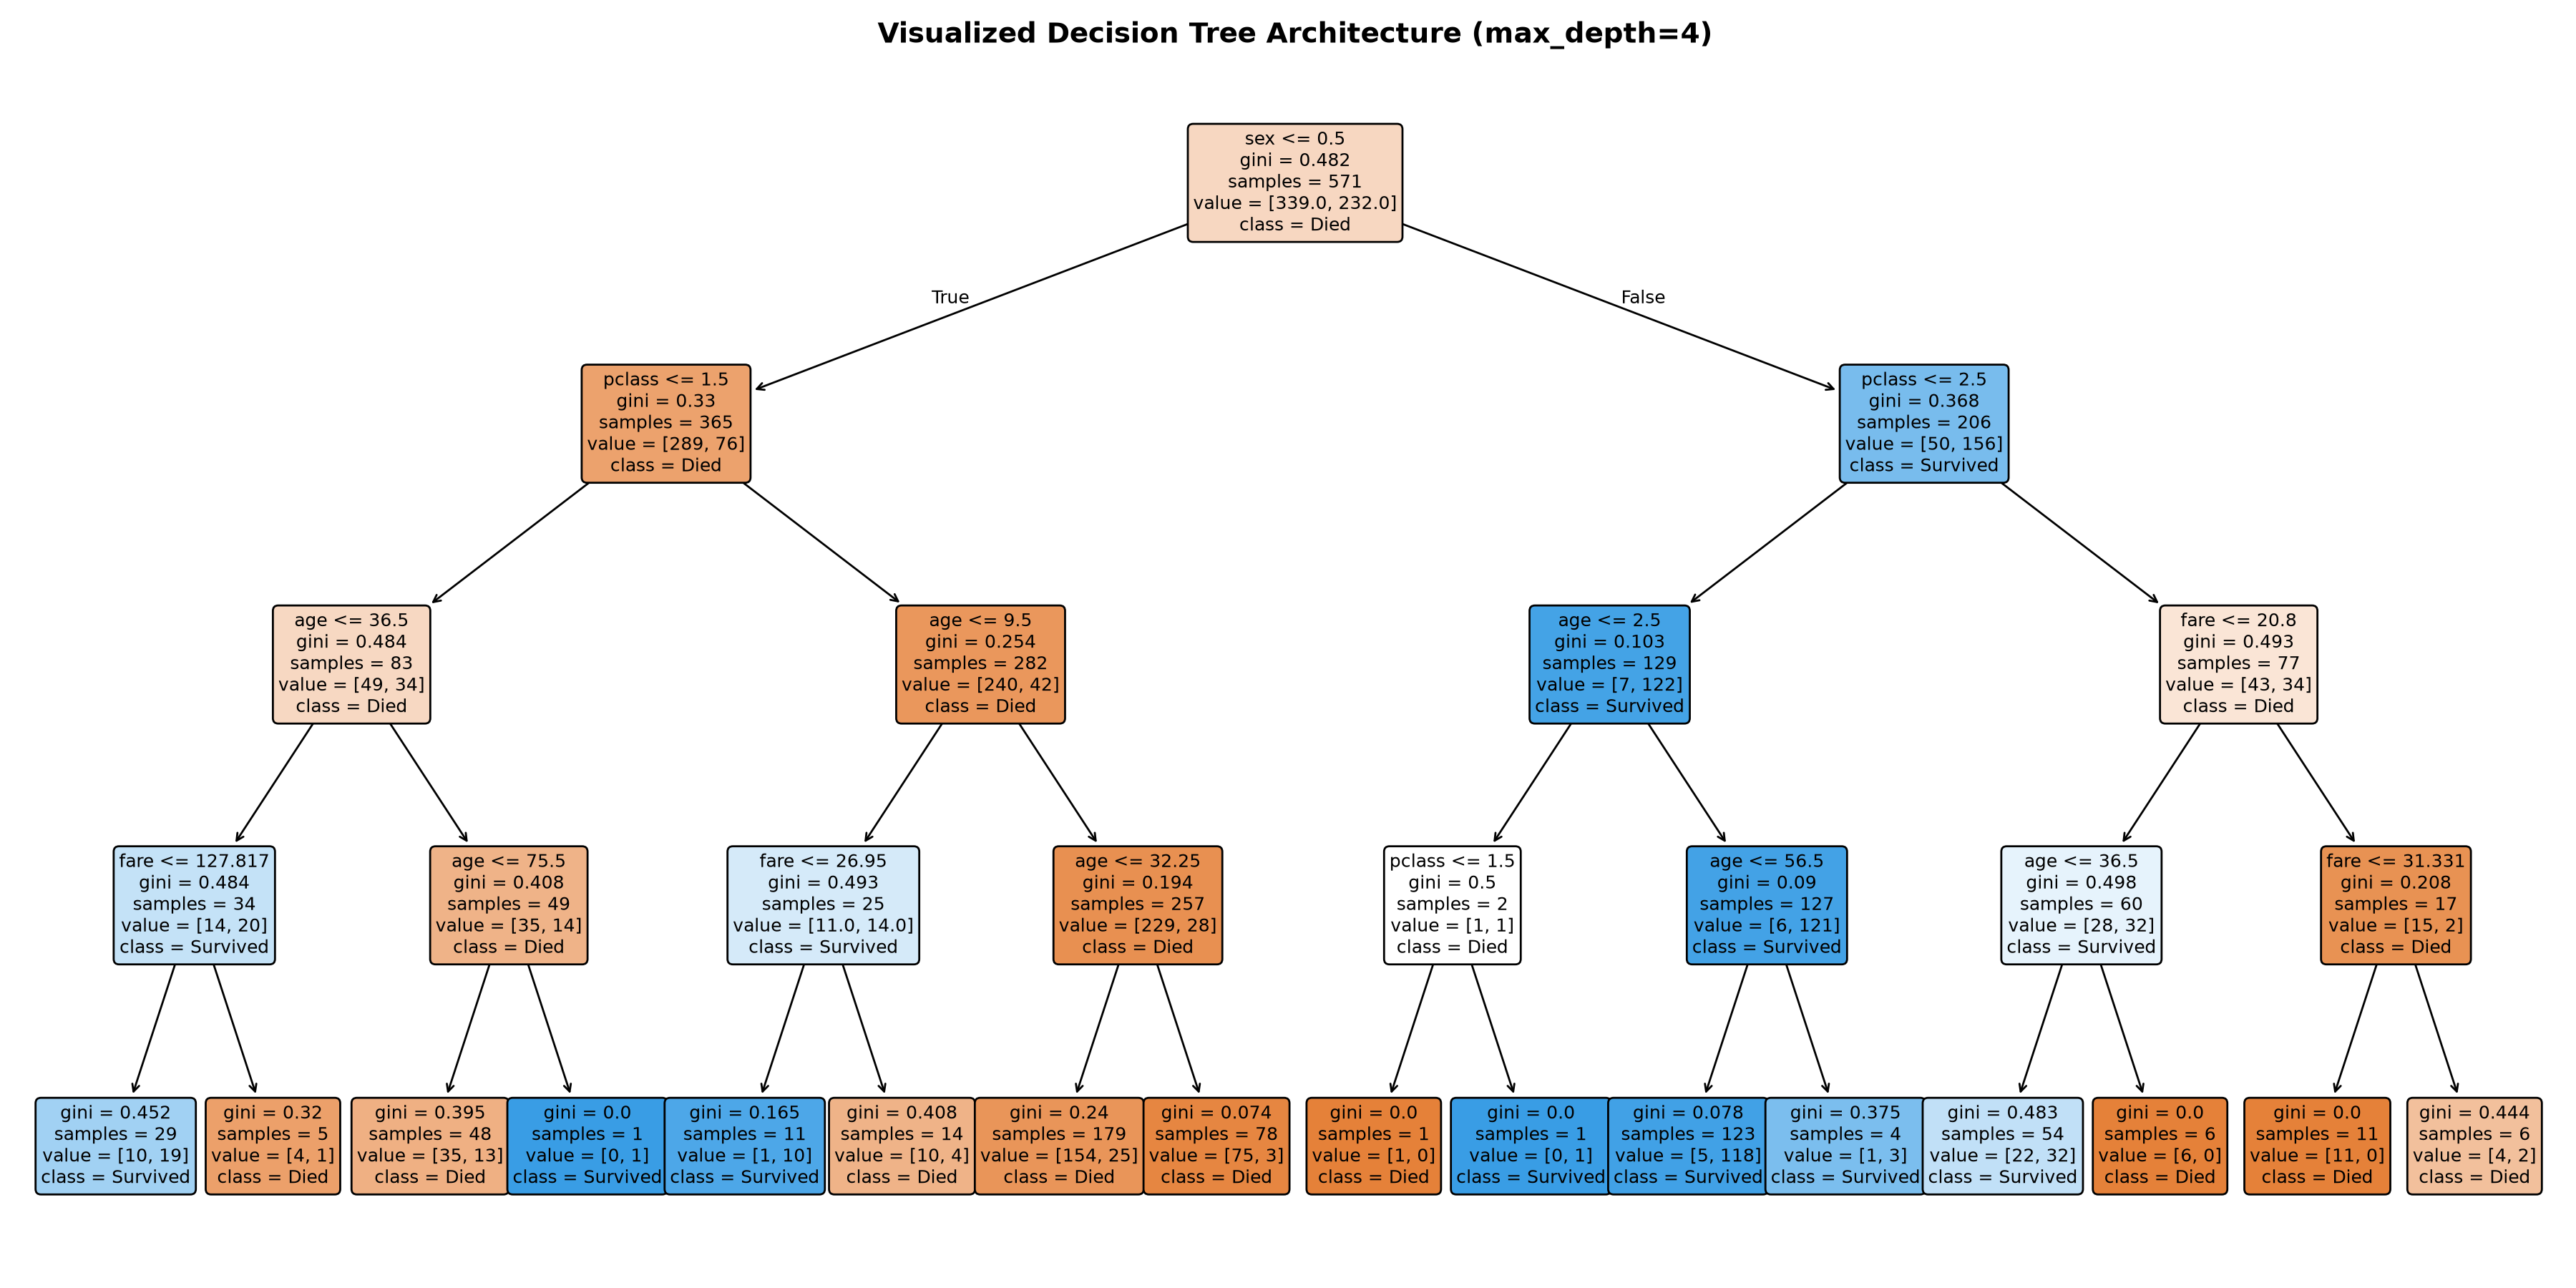

In [9]:
plt.figure(figsize=(18, 9))
plot_tree(
    model,
    feature_names=list(X.columns),
    class_names=["Died", "Survived"],
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Visualized Decision Tree Architecture (max_depth=4)", fontsize=14, fontweight="bold", pad=10)
plt.tight_layout()
plt.show()


## Step 7: Test Depth and Overfitting
We systematically vary `max_depth` from 1 to 12 and compare the training accuracy against the testing accuracy to observe the transition from underfitting to optimal fit to overfitting.


Depth  Train Accuracy  Test Accuracy  Generalization Gap
     1           0.779          0.783              -0.004
     2           0.795          0.776               0.019
     3           0.818          0.811               0.007
     4           0.848          0.797               0.050
     5           0.865          0.762               0.103
     6           0.883          0.783               0.099
     7           0.916          0.783               0.133
     8           0.925          0.790               0.134
     9           0.947          0.769               0.178
    10           0.956          0.762               0.194
    11           0.965          0.769               0.196
    12           0.968          0.776               0.192


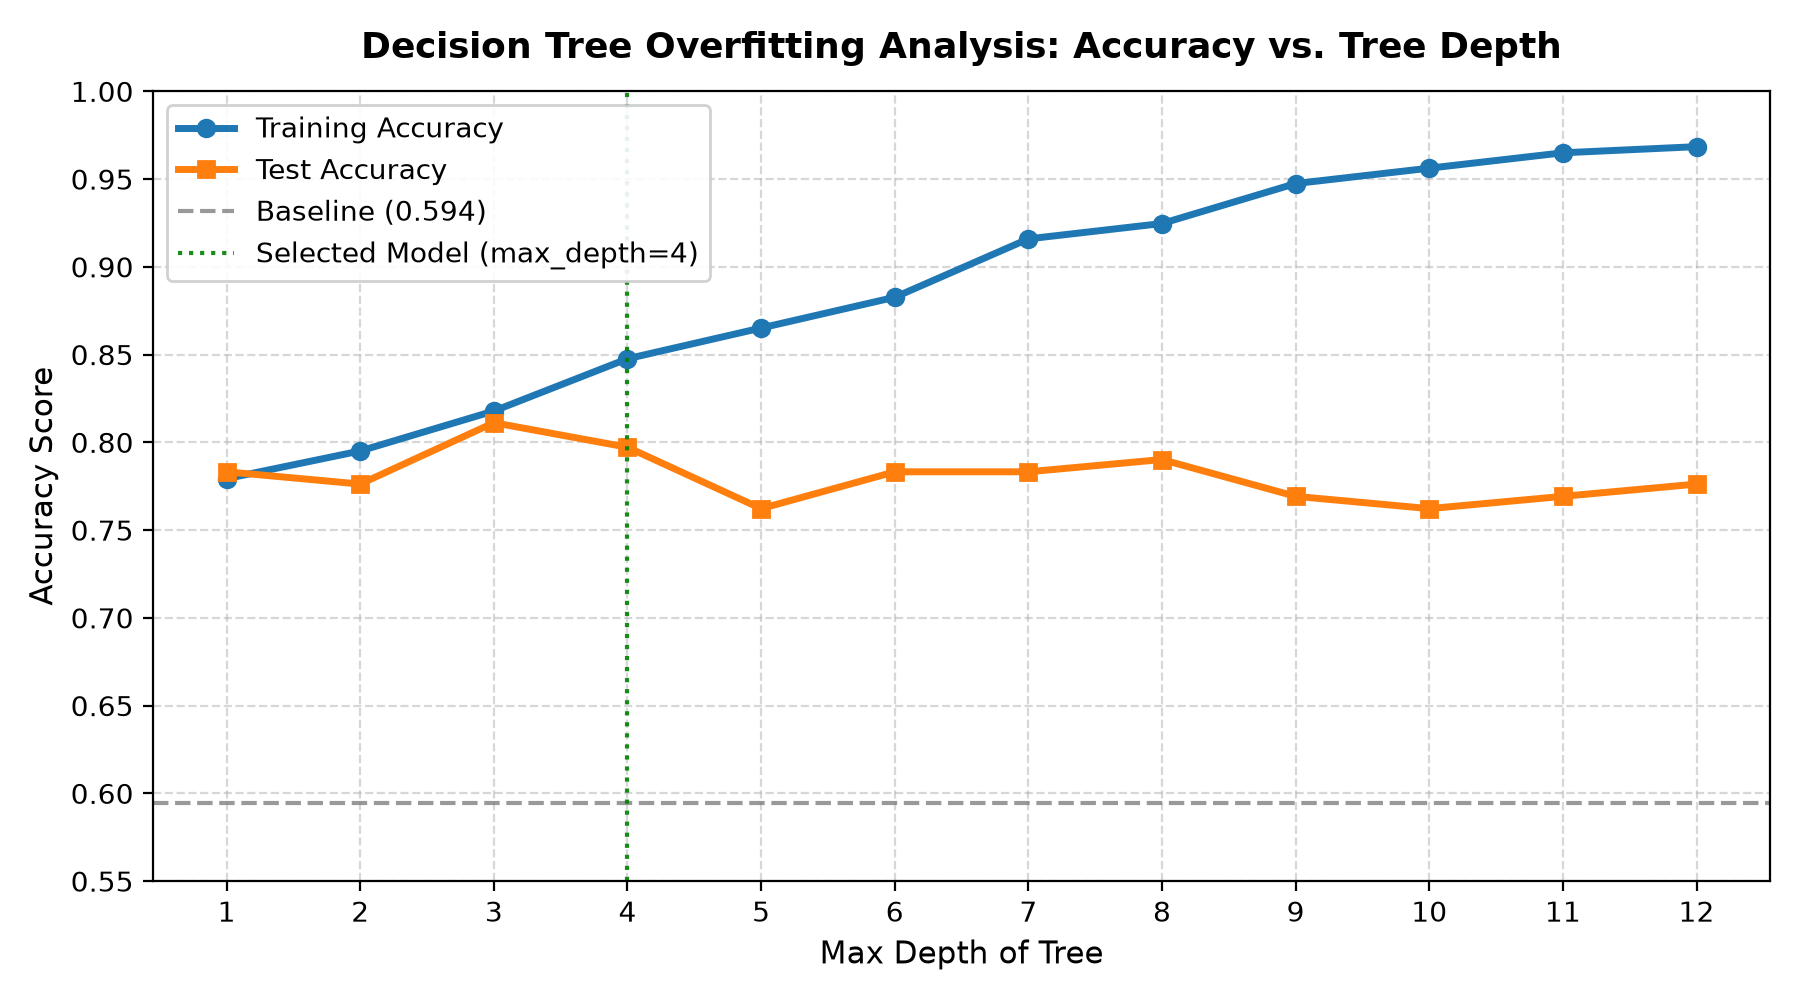

In [10]:
depths = list(range(1, 13))
train_scores = []
test_scores = []

for d in depths:
    dt = DecisionTreeClassifier(max_depth=d, random_state=42)
    dt.fit(X_train, y_train)
    train_scores.append(accuracy_score(y_train, dt.predict(X_train)))
    test_scores.append(accuracy_score(y_test, dt.predict(X_test)))

# Display comparison table
depth_df = pd.DataFrame({
    "Depth": depths,
    "Train Accuracy": [round(x, 3) for x in train_scores],
    "Test Accuracy": [round(x, 3) for x in test_scores],
    "Generalization Gap": [round(tr - te, 3) for tr, te in zip(train_scores, test_scores)]
})
print(depth_df.to_string(index=False))

# Plotting Training vs. Test Accuracy across depths
plt.figure(figsize=(10, 5))
plt.plot(depths, train_scores, marker="o", color="#1f77b4", linewidth=2.5, label="Training Accuracy")
plt.plot(depths, test_scores, marker="s", color="#ff7f0e", linewidth=2.5, label="Test Accuracy")
plt.axhline(baseline, color="gray", linestyle="--", alpha=0.8, label=f"Naive Baseline ({baseline:.3f})")
plt.axvline(4, color="green", linestyle=":", alpha=0.9, label="Selected Model (max_depth=4)")

plt.title("Decision Tree Overfitting Analysis: Accuracy vs. Tree Depth", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Max Depth of Tree", fontsize=11)
plt.ylabel("Accuracy Score", fontsize=11)
plt.xticks(depths)
plt.ylim(0.55, 1.0)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(frameon=True, facecolor="white", framealpha=0.9)
plt.tight_layout()
plt.show()


### Why Very Deep Trees Do Worse on New Data (The Mechanics of Overfitting)

1. **Memorizing Noise vs. Learning General Patterns:**  
   At shallow depths (e.g., depth 1 to 4), the tree splits on dominant, robust trends (such as `sex` and `pclass`). As `max_depth` increases beyond 6, the tree continues splitting until terminal leaves contain only 1 or 2 isolated passengers. The model ends up memorizing specific anomalies, outliers, and noise in the training set rather than learning true underlying population relationships.

2. **Exploding Model Variance:**  
   Unconstrained decision trees have high variance and low bias. Notice how training accuracy reaches **96.8% at depth 12**, while test accuracy declines from **81.1% (depth 3) to 76.2% (depth 10)**. This widening gap (over 19%) is the empirical definition of overfitting.

3. **Pruning & Regularization:**  
   Restricting tree complexity using hyperparameters such as `max_depth=4`, `min_samples_leaf`, or cost-complexity pruning ensures the model retains sufficient bias to generalize well to unseen real-world data.


## Step 8: Write What You Learned (Summary & Limitations)

### 1. Performance Summary
* **Baseline Accuracy:** **59.4%** (predicting the majority class: non-survival).
* **Model Test Accuracy:** **79.7%** (with `max_depth=4`, correctly classifying 114 out of 143 test passengers).
* **Net Value Added:** The decision tree outperforms the baseline by **+20.3 percentage points**.

### 2. Feature Importances
* **`sex` (55% importance):** The single most decisive factor in survival. The evacuation strictly prioritized women, leading to dramatically higher female survival rates.
* **`pclass` (24% importance):** Higher socioeconomic status meant cabins situated on upper decks nearer to the lifeboats, as well as preferential evacuation protocols.
* **`age` (14% importance) & `fare` (8% importance):** Children were given priority over adult males, while higher fares correlated with superior cabin placement.

### 3. Key Model Limitations
1. **Missing Data Loss (`dropna` impact):** Dropping rows with missing values reduced the sample size from 891 to 714 passengers. Age had 177 missing values, which were disproportionately concentrated in 3rd class passengers. Excluding them may introduce survivor selection bias.
2. **High Variance of Single Trees:** A single decision tree is notorious for high sensitivity to small changes in the training data (a different random seed can alter top split thresholds). Moving to an ensemble method like a Random Forest would provide much greater predictive stability.
3. **Omission of Contextual Features:** Important predictive features present in the broader Titanic data—such as family size (`sibsp` + `parch`), title extracted from passenger name (e.g., 'Master' for boys), and cabin deck—were excluded to adhere to the core 4-feature scope.
